In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
import pytensor
import warnings

warnings.filterwarnings('ignore')

def run_analysis(data_filename, results_filename="results.pkl"):
    """
    Loads data from a CSV file, builds and samples a Bayesian hierarchical model using PyMC,
    computes the variance decomposition for the latent scale parameters, and saves key results to a file.
    
    Parameters:
      data_filename (str): Name of the CSV file containing the data.
      results_filename (str): Name of the file to save the results (default "results.pkl").
      
    The saved dictionary contains:
      - "trace": The InferenceData object from MCMC.
      - "variance_decomposition": A dictionary with keys 'total_variance', 'perc_c', 'perc_l', 'perc_p', 'perc_o'.
      - "effective_scales": A dictionary with keys 'S_est', 'LN_est', 'PN_est', 'ON_est'.
      - "data": The preprocessed pandas DataFrame.
    """
    
    # Set PyTensor flags before any PyTensor-related imports
    os.environ["PYTENSOR_DEVICE"] = "cpu"
    os.environ["PYTENSOR_FLOATX"] = "float64"
    os.environ["PYTENSOR_COMPUTE_TEST_VALUE"] = "ignore"
    
    print("Loading data from", data_filename)
    data = pd.read_csv(data_filename)
    print("Data head:")
    print(data.head())
    
    # Create integer indices.
    data['expert_idx'] = pd.Categorical(data['id']).codes
    data['case_idx'] = pd.Categorical(data['item']).codes
    data['occ_idx'] = pd.Categorical(data['t']).codes
    
    # Get dimensions.
    n_experts = data['expert_idx'].nunique()
    n_cases = data['case_idx'].nunique()
    n_obs = data.shape[0]
    
    print("\nDataset summary:")
    print(f"Number of experts: {n_experts}")
    print(f"Number of cases: {n_cases}")
    print(f"Number of observations: {n_obs}")
    
    # Build and sample from the PyMC model using non-centered parameterizations for all latent variables.
    print("\nBuilding model...")
    with pm.Model() as model:
        # Priors for scale parameters.
        sigma_c = pm.HalfNormal("sigma_c", sigma=1)
        sigma_l = pm.HalfNormal("sigma_l", sigma=1)
        sigma_p = pm.HalfNormal("sigma_p", sigma=1)
        sigma_o = pm.HalfNormal("sigma_o", sigma=1)
        intercept = pm.Normal("intercept", mu=0, sigma=10)
        
        # Non-centered latent variables for cases, experts, and their interactions.
        z_c = pm.Normal("z_c", mu=0, sigma=1, shape=n_cases)
        c = pm.Deterministic("c", z_c * sigma_c)
        
        z_l = pm.Normal("z_l", mu=0, sigma=1, shape=n_experts)
        l = pm.Deterministic("l", z_l * sigma_l)
        
        z_p = pm.Normal("z_p", mu=0, sigma=1, shape=(n_experts, n_cases))
        p = pm.Deterministic("p", z_p * sigma_p)
        
        # Non-centered parameterization for observation-level effects.
        z_o = pm.Normal("z_o", mu=0, sigma=1, shape=n_obs)
        o = pm.Deterministic("o", z_o * sigma_o)
        
        # Linear predictor: use the indices as before.
        z = (intercept +
             c[data['case_idx'].values] +
             l[data['expert_idx'].values] +
             p[data['expert_idx'].values, data['case_idx'].values] +
             o)
        
        # Likelihood.
        y_obs = pm.Bernoulli("y_obs", logit_p=z, observed=data['Y'].values)
        
        # Setup monitoring for selected parameters.
        monitor_vars = ['sigma_c', 'sigma_l', 'sigma_p', 'sigma_o', 'intercept']
        diagnostics = None  # (Not using a live callback here.)
        
        print("\nSampling...")
        trace = pm.sample(
            draws=5000,
            tune=2000,
            chains=10,
            cores=6,
            random_seed=42,
            return_inferencedata=True,
            nuts_sampler='numpyro',
            init='jitter+adapt_diag',
            progressbar=True,
            target_accept=0.98
        )
    
    # Post-sampling analysis.
    print("\nPosterior Summary:")
    summary = az.summary(trace, var_names=monitor_vars)
    print(summary)
    
    # Extract posterior samples for the scale parameters (flattening across chains and draws)
    sigma_c_samples = trace.posterior['sigma_c'].values.flatten()
    sigma_l_samples = trace.posterior['sigma_l'].values.flatten()
    sigma_p_samples = trace.posterior['sigma_p'].values.flatten()
    sigma_o_samples = trace.posterior['sigma_o'].values.flatten()
    
    # Compute the variance for each component (variance = sigma^2)
    var_c = np.mean(sigma_c_samples ** 2)
    var_l = np.mean(sigma_l_samples ** 2)
    var_p = np.mean(sigma_p_samples ** 2)
    var_o = np.mean(sigma_o_samples ** 2)
    
    # Calculate the total variance as the sum of the four component variances.
    total_variance = var_c + var_l + var_p + var_o
    
    # Compute percentage contributions based on variances.
    perc_c = (var_c / total_variance) * 100
    perc_l = (var_l / total_variance) * 100
    perc_p = (var_p / total_variance) * 100
    perc_o = (var_o / total_variance) * 100
    
    print("\nVariance Decomposition:")
    print(f"Total Variance (sum of components): {total_variance:.3f}")
    print("Percentage contributions:")
    print(f"  Signal (case) variance:         {perc_c:.2f}%")
    print(f"  Level noise (expert) variance:    {perc_l:.2f}%")
    print(f"  Pattern noise (interaction) variance: {perc_p:.2f}%")
    print(f"  Occasion noise (observation-level) variance: {perc_o:.2f}%")
    
    # Compute effective scale estimates as the square roots of the variances.
    S_est = np.sqrt(var_c)
    LN_est = np.sqrt(var_l)
    PN_est = np.sqrt(var_p)
    ON_est = np.sqrt(var_o)
    
    print("\nEffective scale estimates:")
    print(f"Signal (S): {S_est:.2f}")
    print(f"Level Noise (LN): {LN_est:.2f}")
    print(f"Pattern Noise (PN): {PN_est:.2f}")
    print(f"Occasion Noise (ON): {ON_est:.2f}")
    
    # Prepare results dictionary.
    results = {
        "trace": trace,
        "variance_decomposition": {
            "total_variance": total_variance,
            "perc_c": perc_c,
            "perc_l": perc_l,
            "perc_p": perc_p,
            "perc_o": perc_o
        },
        "effective_scales": {
            "S_est": S_est,
            "LN_est": LN_est,
            "PN_est": PN_est,
            "ON_est": ON_est
        },
        "data": data
    }
    
    # Save results to file (if desired; currently commented out).
    # with open(results_filename, "wb") as f:
    #     pickle.dump(results, f)
    # print(f"\nResults saved to {results_filename}")

    #==================================
    # --- After sampling is done ---
    
    # Extract posterior means for the latent variables.
    # (We average over chains and draws.)
    c_est = trace.posterior['c'].mean(dim=["chain", "draw"]).values  # shape: (n_cases,) e.g. (50,)
    l_est = trace.posterior['l'].mean(dim=["chain", "draw"]).values  # shape: (n_experts,) e.g. (20,)
    p_est = trace.posterior['p'].mean(dim=["chain", "draw"]).values  # shape: (n_experts, n_cases) e.g. (20, 50)
    o_est = trace.posterior['o'].mean(dim=["chain", "draw"]).values  # shape: (n_obs,) e.g. (20*50*2,)
    
    # Create a DataFrame using your original data's indices.
    # We assume your DataFrame "data" has the columns 'expert_idx', 'case_idx', and 'occ_idx'.
    df_latents = data[['expert_idx', 'case_idx', 'occ_idx']].copy()
    
    # For each row, add:
    # - c: the case-level latent (look up by 'case_idx')
    # - l: the expert-level latent (look up by 'expert_idx')
    # - p: the expert-case interaction (look up by both indices)
    # - o: the observation-level latent effect (assumed to be in the same order as data rows)
    df_latents['c'] = df_latents['case_idx'].apply(lambda j: c_est[int(j)])
    df_latents['l'] = df_latents['expert_idx'].apply(lambda i: l_est[int(i)])
    df_latents['p'] = df_latents.apply(lambda row: p_est[int(row['expert_idx']), int(row['case_idx'])], axis=1)
    df_latents['o'] = o_est
    
    # Optionally, rename the index columns to i, j, and t
    df_latents.rename(columns={"expert_idx": "i", "case_idx": "j", "occ_idx": "t"}, inplace=True)
    
    # Save the resulting DataFrame to a CSV file whose name is based on the data file name.
    latent_csv_filename = data_filename.replace(".csv", "_latent_effects.csv")
    df_latents.to_csv(latent_csv_filename, index=False)
    print("Estimated random effects saved to", latent_csv_filename)

    #==================================
    
    return results

# Call the function for each dataset, saving latent variables to separate CSV files.
results1 = run_analysis("dataQ1.csv", "resultsQ1.pkl")
results3 = run_analysis("dataQ2.csv", "resultsQ2.pkl")
results2 = run_analysis("dataQEEG.csv", "resultsQEEG.pkl")


Loading data from dataQ1.csv
Data head:
   id  item  t  Y
0   1     1  1  0
1   1     2  1  0
2   1     3  1  0
3   1     4  1  0
4   1     5  1  1

Dataset summary:
Number of experts: 20
Number of cases: 50
Number of observations: 2000

Building model...

Sampling...


Compiling...
Compilation time = 0:00:02.057552
Sampling...


  0%|          | 0/7000 [00:00<?, ?it/s]

  0%|          | 0/7000 [00:00<?, ?it/s]

  0%|          | 0/7000 [00:00<?, ?it/s]

...

  0%|          | 0/7000 [00:00<?, ?it/s]

  0%|          | 0/7000 [00:00<?, ?it/s]

  0%|          | 0/7000 [00:00<?, ?it/s]

Sampling time = 0:00:01.011415
Transforming variables...
Transformation time = 0:03:48.562813



Posterior Summary:
            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
sigma_c    1.940  0.270   1.460    2.449      0.004    0.002    6203.0   
sigma_l    1.661  0.298   1.132    2.219      0.003    0.002   10360.0   
sigma_p    1.795  0.218   1.396    2.206      0.003    0.002    5188.0   
sigma_o    0.490  0.367   0.000    1.146      0.008    0.005    2071.0   
intercept  1.719  0.497   0.798    2.681      0.006    0.003    7843.0   

           ess_tail  r_hat  
sigma_c     10459.0    1.0  
sigma_l     20679.0    1.0  
sigma_p      7569.0    1.0  
sigma_o      3400.0    1.0  
intercept   13134.0    1.0  

Variance Decomposition:
Total Variance (sum of components): 10.325
Percentage contributions:
  Signal (case) variance:         37.15%
  Level noise (expert) variance:    27.57%
  Pattern noise (interaction) variance: 31.65%
  Occasion noise (observation-level) variance: 3.63%

Effective scale estimates:
Signal (S): 1.96
Level Noise (LN): 1.69
Pattern Noise (

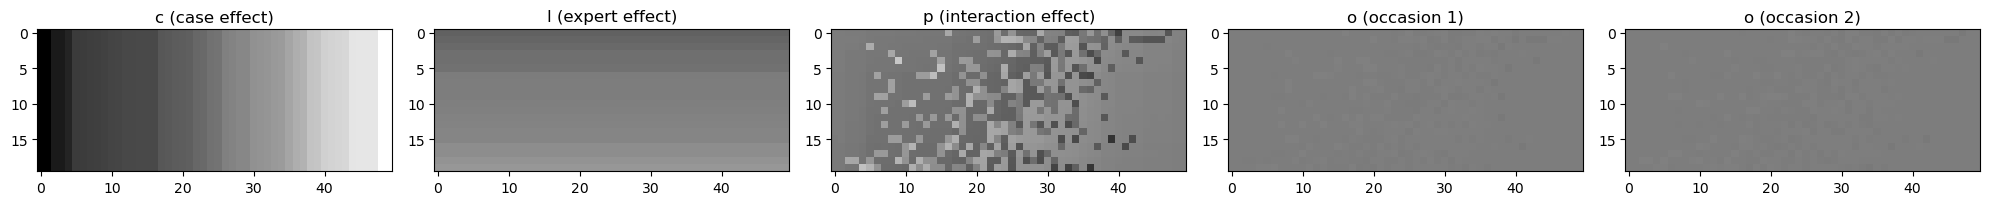

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Load CSV and prepare pivot tables
# -----------------------------
df = pd.read_csv("dataQ2_latent_effects.csv")

# Ensure the index columns are integers.
df['i'] = df['i'].astype(int)
df['j'] = df['j'].astype(int)
df['t'] = df['t'].astype(int)

# Create pivot tables (20 x 50 matrices) for each latent effect.
df_c  = df.pivot_table(index='i', columns='j', values='c', aggfunc='first')
df_l  = df.pivot_table(index='i', columns='j', values='l', aggfunc='first')
df_p  = df.pivot_table(index='i', columns='j', values='p', aggfunc='first')
df_o1 = df[df['t'] == 0].pivot_table(index='i', columns='j', values='o', aggfunc='first')
df_o2 = df[df['t'] == 1].pivot_table(index='i', columns='j', values='o', aggfunc='first')

# -----------------------------
# Sorting: sort rows (i) by expert latent (l) and columns (j) by case latent (c)
# (Note: Although your instruction said to sort i based on c and j based on l,
#  it makes more sense to sort experts by l and cases by c.)
# -----------------------------
# For experts, l is constant across cases so we use the first column.
expert_order = df_l.iloc[:, 0].sort_values().index
# For cases, c is constant across experts so we use the first row.
case_order   = df_c.iloc[0].sort_values().index

# Reindex all matrices using the determined order.
df_c  = df_c.reindex(index=expert_order, columns=case_order)
df_l  = df_l.reindex(index=expert_order, columns=case_order)
df_p  = df_p.reindex(index=expert_order, columns=case_order)
df_o1 = df_o1.reindex(index=expert_order, columns=case_order)
df_o2 = df_o2.reindex(index=expert_order, columns=case_order)

# -----------------------------
# Determine global min and max across all matrices for consistent grayscale scaling.
# -----------------------------
global_min = min(df_c.min().min(), df_l.min().min(), df_p.min().min(), 
                 df_o1.min().min(), df_o2.min().min())
global_max = max(df_c.max().max(), df_l.max().max(), df_p.max().max(), 
                 df_o1.max().max(), df_o2.max().max())

# -----------------------------
# Preview: Plot all 5 matrices side by side
# -----------------------------
fig, axs = plt.subplots(1, 5, figsize=(20, 4))

axs[0].imshow(df_c.values, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
axs[0].set_title("c (case effect)")

axs[1].imshow(df_l.values, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
axs[1].set_title("l (expert effect)")

axs[2].imshow(df_p.values, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
axs[2].set_title("p (interaction effect)")

axs[3].imshow(df_o1.values, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
axs[3].set_title("o (occasion 1)")

axs[4].imshow(df_o2.values, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
axs[4].set_title("o (occasion 2)")

plt.tight_layout()
plt.show()

# -----------------------------
# Save each matrix as an individual PNG file.
# Each file will have:
#  - No title or axes
#  - No extra white space (using tight layout options)
#  - 300 dpi resolution
# -----------------------------
# Dictionary mapping filename to the corresponding matrix values.
matrices = {
    "matrix_c.png":  df_c.values,
    "matrix_l.png":  df_l.values,
    "matrix_p.png":  df_p.values,
    "matrix_o1.png": df_o1.values,
    "matrix_o2.png": df_o2.values,
}

# Loop over each matrix, create a figure, remove axes and whitespace, and save.
for fname, mat in matrices.items():
    # Set figure size to approximate the 20x50 (taller than wide vs. wider than tall)
    # Here, 5 x 2 gives a 2.5:1 aspect ratio (50/20 = 2.5).
    fig, ax = plt.subplots(figsize=(5, 2))
    ax.imshow(mat, cmap="gray", vmin=global_min, vmax=global_max,
              aspect='equal', interpolation='none')
    ax.axis('off')  # remove axes
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(fname, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close()


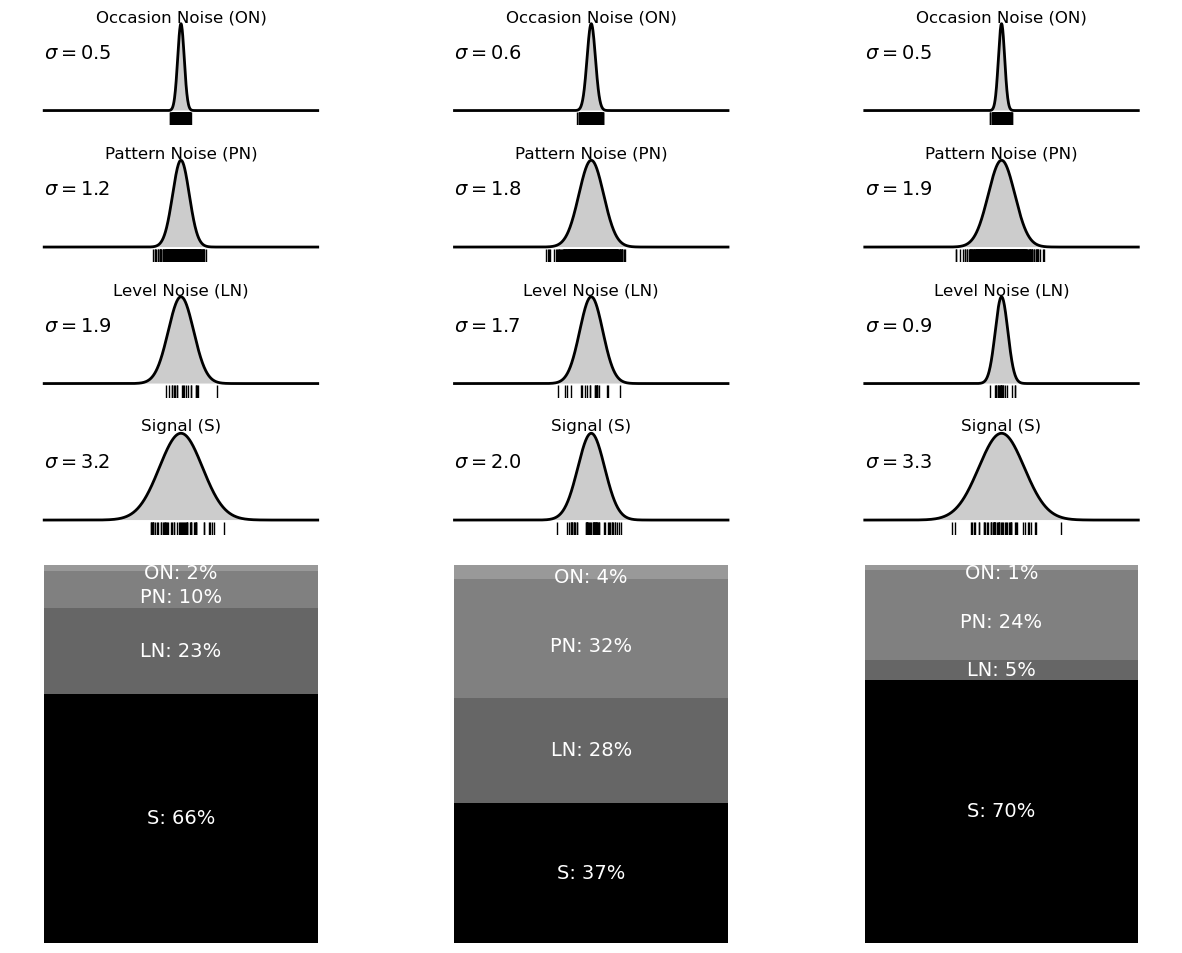

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import scipy.stats as st

#--------------------------------------------------
# Helper Function: fcn_gaussian_plot (mimicking MATLAB)
#--------------------------------------------------
def fcn_gaussian_plot(ax, x, s, titleStr):
    """
    Mimics the MATLAB fcnGaussianPlot.
    Fits a Gaussian to data x (using a fixed sigma value s),
    plots vertical tick marks at y=-0.1, fills under the normalized Gaussian density,
    overlays the fitted curve, and adds a text label showing the fitted sigma.
    All ticks and axes are removed.
    """
    # Generate x values for plotting the fitted curve.
    xx = np.linspace(-20, 20, 1000)
    y = st.norm.pdf(xx, loc=0, scale=s)
    y = y / np.max(y)  # Normalize so that max(y)==1.
    
    # Plot vertical tick marks at each data point at y = -0.1.
    ax.plot(x, np.full_like(x, -0.1), 'k|', markersize=10)
    
    # Fill the area under the fitted curve.
    ax.fill_between(xx, 0, y, color=[0.8, 0.8, 0.8], edgecolor='none')
    # Plot the fitted Gaussian curve.
    ax.plot(xx, y, 'k', linewidth=2)
    
    # Add text showing the fitted sigma.
    ax.text(-20, 0.6, f"$\\sigma = {s:.1f}$", fontsize=14)
    
    # Remove ticks and axis labels.
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('off')
    # Adjust the title placement with extra padding (adjust pad value as needed)
    # ax.set_title(titleStr, pad=20)
    ax.set_title(titleStr, y=0.73)
    ax.set_xlim([-25, 25])

#--------------------------------------------------
# Helper Function: fcn_plot_stacked_bars_percent (vertical version using variance percentages)
#--------------------------------------------------
def fcn_plot_stacked_bars_percent(ax, perc_array, labels=None, on_offset=1):
    """
    Plots a vertical stacked bar using the given percentages.
    The input perc_array should be an array of percentages (e.g. [perc_c, perc_l, perc_p, perc_o])
    that sum to 100. The labels (if not provided) default to:
         ['S', 'LN', 'PN', 'ON'].
    Text labels are placed at the midpoint of each segment computed from the cumulative sum.
    For the top segment (Occasion Noise), the text is shifted downward by 'on_offset' units
    to ensure it is fully visible.
    """
    if labels is None:
        labels = ['S', 'LN', 'PN', 'ON']
    
    # Define colors (similar to MATLAB's cc matrix).
    cc = np.array([[0, 0, 0],
                   [0.4, 0.4, 0.4],
                   [0.5, 0.5, 0.5],
                   [0.6, 0.6, 0.6]])
    
    # Compute cumulative sums of percentages.
    cumsum_vals = np.cumsum(perc_array)
    prev = 0
    for i, val in enumerate(perc_array):
        # Compute the midpoint of the segment.
        mid = (prev + cumsum_vals[i]) / 2
        # For the top segment (last one: ON), shift the text down by on_offset units.
        if i == len(perc_array) - 1:
            mid = mid - 1.5
        if i == len(perc_array) - 2:
            mid = mid - 2
        ax.bar(0, val, bottom=prev, color=cc[i], width=0.8, edgecolor='none')
        ax.text(0, mid, f"{labels[i]}: {val:.0f}%", ha='center', va='center', color='white', fontsize=14)
        prev = cumsum_vals[i]
    
    ax.set_xlim(-0.5, 0.5)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis('off')

#--------------------------------------------------
# Plotting for all three sets of results
#--------------------------------------------------

# List of your results dictionaries and titles for each column
results_list = [results1, results2, results3]
titles = ["", "", ""]

# Create the overall figure. Adjust the figsize if needed.
fig = plt.figure(figsize=(15, 12))
# Create a 7 (rows) x 3 (columns) grid.
gs = gridspec.GridSpec(7, 3, figure=fig, hspace=0.3)

# Loop over each results set to plot in its respective column.
for col, (res, col_title) in enumerate(zip(results_list, titles)):
    # Extract the trace from the results dictionary.
    trace = res["trace"]
    
    # Extract posterior samples for the scale parameters.
    sigma_c_samples = trace.posterior['sigma_c'].values.flatten()
    sigma_l_samples = trace.posterior['sigma_l'].values.flatten()
    sigma_p_samples = trace.posterior['sigma_p'].values.flatten()
    sigma_o_samples = trace.posterior['sigma_o'].values.flatten()
    
    # Compute the variance for each component (variance = sigma^2)
    var_c = np.mean(sigma_c_samples ** 2)
    var_l = np.mean(sigma_l_samples ** 2)
    var_p = np.mean(sigma_p_samples ** 2)
    var_o = np.mean(sigma_o_samples ** 2)
    
    # Calculate the total variance as the sum of the four component variances.
    total_variance = var_c + var_l + var_p + var_o
    
    # Compute percentage contributions.
    perc_c = (var_c / total_variance) * 100
    perc_l = (var_l / total_variance) * 100
    perc_p = (var_p / total_variance) * 100
    perc_o = (var_o / total_variance) * 100
    
    # Compute effective scale estimates (square roots of the variances).
    S_est = np.sqrt(var_c)
    LN_est = np.sqrt(var_l)
    PN_est = np.sqrt(var_p)
    ON_est = np.sqrt(var_o)
    
    # ----------------------------
    # Gaussian plot for Occasion Noise (ON)
    # ----------------------------
    ax1 = fig.add_subplot(gs[0, col])
    x_on = np.random.randn(50 * 20) * ON_est
    fcn_gaussian_plot(ax1, x_on, ON_est, f"Occasion Noise (ON)\n{col_title}")
    
    # ----------------------------
    # Gaussian plot for Pattern Noise (PN)
    # ----------------------------
    ax2 = fig.add_subplot(gs[1, col])
    x_pn = np.random.randn(20 * 50) * PN_est
    fcn_gaussian_plot(ax2, x_pn, PN_est, f"Pattern Noise (PN)\n{col_title}")
    
    # ----------------------------
    # Gaussian plot for Level Noise (LN)
    # ----------------------------
    ax3 = fig.add_subplot(gs[2, col])
    x_ln = np.random.randn(20) * LN_est
    fcn_gaussian_plot(ax3, x_ln, LN_est, f"Level Noise (LN)\n{col_title}")
    
    # ----------------------------
    # Gaussian plot for Signal (S)
    # ----------------------------
    ax4 = fig.add_subplot(gs[3, col])
    x_s = np.random.randn(50) * S_est
    fcn_gaussian_plot(ax4, x_s, S_est, f"Signal (S)\n{col_title}")
    
    # ----------------------------
    # Vertical Stacked Bar Plot (variance percentages)
    # ----------------------------
    ax5 = fig.add_subplot(gs[4:, col])
    perc_array = [perc_c, perc_l, perc_p, perc_o]
    fcn_plot_stacked_bars_percent(ax5, perc_array)

# Adjust layout for clarity.
plt.tight_layout()

# Save the figure as a publication-ready PNG file.
plt.savefig("Figure3.png", dpi=300, bbox_inches='tight')

# Optionally display the figure.
plt.show()


Adjusting latent Q1 'j' values by adding 1 to match raw data items.
Adjusting latent Q2 'j' values by adding 1 to match raw data items.


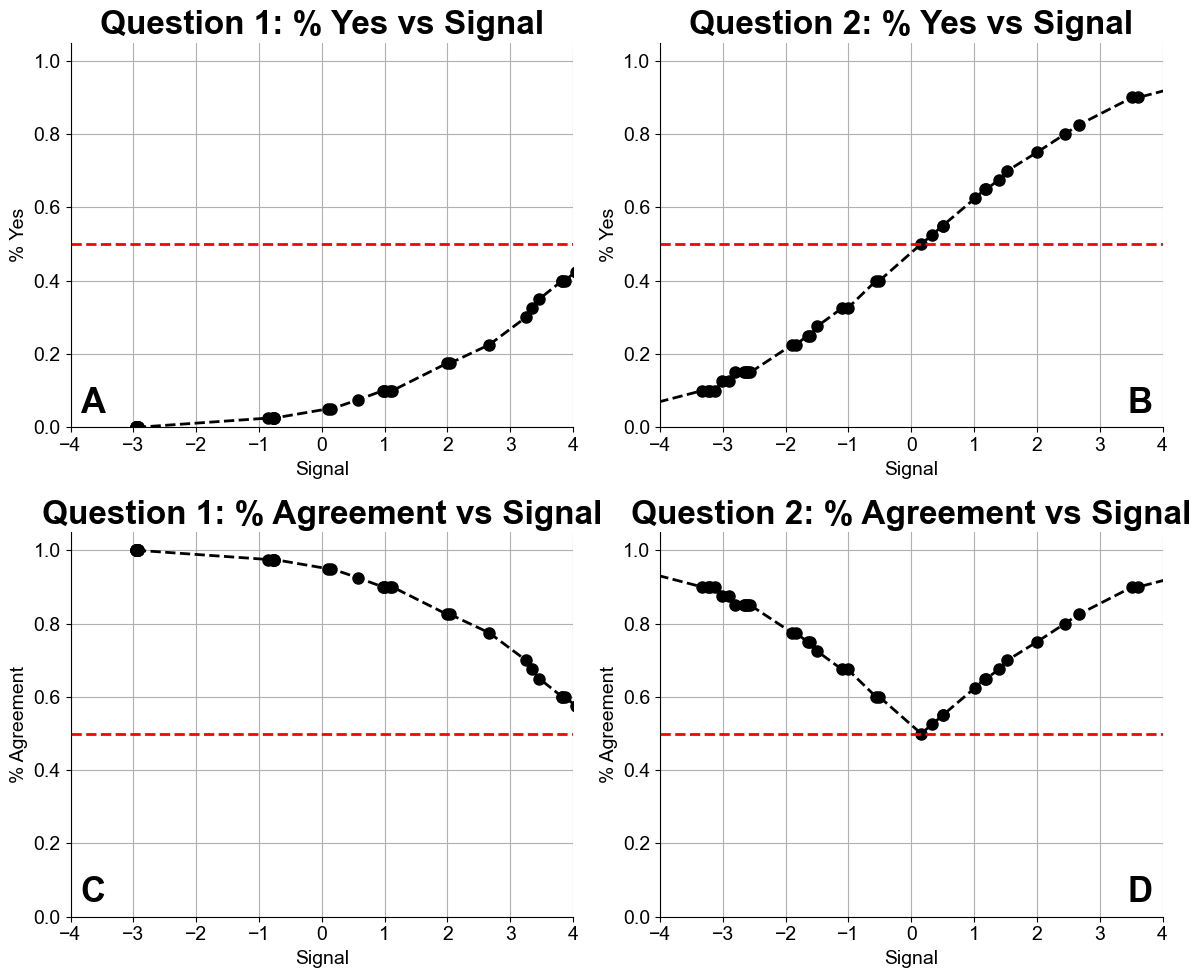

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------
# Helper: Compute percent agreement from percent yes.
# For each case, if p is the fraction of "1" responses, then agreement = max(p, 1-p).
# ------------------------------
def compute_agreement(p):
    return max(p, 1 - p)

# ------------------------------
# Process Q1
# ------------------------------

# Load raw responses for Q1 (expected columns: id, item, t, Y)
df_q1 = pd.read_csv('dataQ1.csv')

# Group raw responses by case (item) and compute percent yes.
q1_stats = df_q1.groupby('item')['Y'].mean().reset_index()
q1_stats.rename(columns={'Y': 'percent_yes'}, inplace=True)
q1_stats['percent_agreement'] = q1_stats['percent_yes'].apply(compute_agreement)

# Load latent effects for Q1 (expected columns: i, j, t, c, l, p, o)
latent_q1 = pd.read_csv('dataQ1_latent_effects.csv')
# Make sure the case indicator (j) is numeric.
latent_q1['j'] = pd.to_numeric(latent_q1['j'])

# Check raw "item" values.
raw_items = sorted(df_q1['item'].unique())
# Check latent items:
latent_items = sorted(latent_q1['j'].unique())

# If the raw data are 1-indexed (e.g. 1 to 50) and latent file is 0-indexed (e.g. 0 to 49),
# then adjust the latent file by adding 1.
if max(raw_items) == max(latent_items) + 1:
    print("Adjusting latent Q1 'j' values by adding 1 to match raw data items.")
    latent_q1['j'] = latent_q1['j'] + 1

# Now, extract exactly 50 values for c (signal strength) by grouping by "j"
latent_q1_c = latent_q1.groupby('j')['c'].first().reset_index()
latent_q1_c.rename(columns={'j': 'item', 'c': 'signal'}, inplace=True)

# Ensure we have exactly 50 cases.
if latent_q1_c.shape[0] != 50:
    print(f"Warning: Expected 50 cases for Q1 latent signal but got {latent_q1_c.shape[0]}.")

# Merge the computed response stats with the latent signal.
q1_merged = pd.merge(q1_stats, latent_q1_c, on='item', how='inner')
# Sort by signal if desired.
q1_merged.sort_values('signal', inplace=True)

# ------------------------------
# Process Q2 (similarly)
# ------------------------------
df_q2 = pd.read_csv('dataQ2.csv')
q2_stats = df_q2.groupby('item')['Y'].mean().reset_index()
q2_stats.rename(columns={'Y': 'percent_yes'}, inplace=True)
q2_stats['percent_agreement'] = q2_stats['percent_yes'].apply(compute_agreement)

latent_q2 = pd.read_csv('dataQ2_latent_effects.csv')
latent_q2['j'] = pd.to_numeric(latent_q2['j'])
latent_items_q2 = sorted(latent_q2['j'].unique())
if max(raw_items) == max(latent_items_q2) + 1:
    print("Adjusting latent Q2 'j' values by adding 1 to match raw data items.")
    latent_q2['j'] = latent_q2['j'] + 1

latent_q2_c = latent_q2.groupby('j')['c'].first().reset_index()
latent_q2_c.rename(columns={'j': 'item', 'c': 'signal'}, inplace=True)
if latent_q2_c.shape[0] != 50:
    print(f"Warning: Expected 50 cases for Q2 latent signal but got {latent_q2_c.shape[0]}.")

q2_merged = pd.merge(q2_stats, latent_q2_c, on='item', how='inner')
q2_merged.sort_values('signal', inplace=True)

# ------------------------------
# Plotting with improved aesthetics
# ------------------------------

# Set font and style properties for publication.
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({'font.size': 14})

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.patch.set_facecolor('w')

def beautify(ax):
    # Remove top and right spines for a cleaner look.
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    # Set ticks only on left and bottom.
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')

# ------------------------------
# Plot: Q1: Percent Yes vs. Signal (Top Left)
# ------------------------------
ax = axs[0, 0]
# Plot the dashed line first then the markers.
ax.plot(q1_merged['signal'], q1_merged['percent_yes'], 'k--', linewidth=2)
ax.plot(q1_merged['signal'], q1_merged['percent_yes'], 'ko', markersize=8)
ax.set_xlabel('Signal')
ax.set_ylabel('% Yes')
ax.set_title('Question 1: % Yes vs Signal', fontsize=24, fontweight='bold')

ax.grid(True)
ax.axis([-4, 4, 0, 1.05])
ax.plot([-4, 4], [0.5, 0.5], 'r--', linewidth=2)
beautify(ax)
# Add panel label "A" in lower left.
ax.text(0.02, 0.02, "A", transform=ax.transAxes,
        fontsize=25, fontweight='bold', va='bottom', ha='left')

# ------------------------------
# Plot: Q1: Percent Agreement vs. Signal (Bottom Left)
# ------------------------------
ax = axs[1, 0]
ax.plot(q1_merged['signal'], q1_merged['percent_agreement'], 'k--', linewidth=2)
ax.plot(q1_merged['signal'], q1_merged['percent_agreement'], 'ko', markersize=8)
ax.set_xlabel('Signal')
ax.set_ylabel('% Agreement')
ax.set_title('Question 1: % Agreement vs Signal', fontsize=24, fontweight='bold')
ax.grid(True)
ax.axis([-4, 4, 0, 1.05])
ax.plot([-4, 4], [0.5, 0.5], 'r--', linewidth=2)
beautify(ax)
# Add panel label "C" in lower left.
ax.text(0.02, 0.02, "C", transform=ax.transAxes,
        fontsize=25, fontweight='bold', va='bottom', ha='left')

# ------------------------------
# Plot: Q2: Percent Yes vs. Signal (Top Right)
# ------------------------------
ax = axs[0, 1]
ax.plot(q2_merged['signal'], q2_merged['percent_yes'], 'k--', linewidth=2)
ax.plot(q2_merged['signal'], q2_merged['percent_yes'], 'ko', markersize=8)
ax.set_xlabel('Signal')
ax.set_ylabel('% Yes')
# Increase the title font size for the Q2 plot.
ax.set_title('Question 2: % Yes vs Signal', fontsize=24, fontweight='bold')
ax.grid(True)
ax.axis([-4, 4, 0, 1.05])
ax.plot([-4, 4], [0.5, 0.5], 'r--', linewidth=2)
beautify(ax)
# Add panel label "B" in lower right.
ax.text(0.98, 0.02, "B", transform=ax.transAxes,
        fontsize=25, fontweight='bold', va='bottom', ha='right')

# ------------------------------
# Plot: Q2: Percent Agreement vs. Signal (Bottom Right)
# ------------------------------
ax = axs[1, 1]
ax.plot(q2_merged['signal'], q2_merged['percent_agreement'], 'k--', linewidth=2)
ax.plot(q2_merged['signal'], q2_merged['percent_agreement'], 'ko', markersize=8)
ax.set_xlabel('Signal')
ax.set_ylabel('% Agreement')
# Increase the title font size for the Q2 plot.
ax.set_title('Question 2: % Agreement vs Signal', fontsize=24, fontweight='bold')
ax.grid(True)
ax.axis([-4, 4, 0, 1.05])
ax.plot([-4, 4], [0.5, 0.5], 'r--', linewidth=2)
beautify(ax)
# Add panel label "D" in lower right.
ax.text(0.98, 0.02, "D", transform=ax.transAxes,
        fontsize=25, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()

# Save the figure as a publication-ready PNG (300 dpi)
plt.savefig("Figure2.png", dpi=300, bbox_inches='tight')
plt.show()


In [5]:
"""
Calculate Cohen's kappa and Fleiss' kappa for inter-rater agreement
to verify the values stated in the paper.
"""

import pandas as pd
import numpy as np
from sklearn.metrics import cohen_kappa_score
from itertools import combinations
from statsmodels.stats.inter_rater import fleiss_kappa

def calculate_kappa_for_dataset(data_file):
    """
    Calculate pairwise Cohen's kappa between all raters and return mean kappa.
    
    Args:
        data_file: Path to CSV file with columns: id, item, t, Y
    
    Returns:
        mean_kappa: Average Cohen's kappa across all rater pairs
        std_kappa: Standard deviation of kappa values
        all_kappas: List of all pairwise kappa values
    """
    # Load data
    df = pd.read_csv(data_file)
    
    # Get unique raters and items
    raters = sorted(df['id'].unique())
    items = sorted(df['item'].unique())
    
    print(f"Dataset: {data_file}")
    print(f"  Raters: {len(raters)}")
    print(f"  Items: {len(items)}")
    print(f"  Occasions: {len(df['t'].unique())}")
    
    # For each rater, get their responses across all items (averaging over occasions)
    rater_responses = {}
    for rater in raters:
        # Get responses for this rater, averaging over occasions
        rater_df = df[df['id'] == rater].groupby('item')['Y'].mean().reset_index()
        # Round to get binary (in case of ties, though unlikely with 2 occasions)
        rater_responses[rater] = rater_df.set_index('item')['Y'].round().astype(int)
    
    # Calculate pairwise Cohen's kappa for all rater pairs
    kappa_values = []
    for r1, r2 in combinations(raters, 2):
        y1 = rater_responses[r1].values
        y2 = rater_responses[r2].values
        # Use labels parameter to handle cases where one rater has all 0s or all 1s
        try:
            kappa = cohen_kappa_score(y1, y2, labels=[0, 1])
            # Only include valid kappa values (not NaN)
            if not np.isnan(kappa):
                kappa_values.append(kappa)
        except:
            # Skip this pair if kappa can't be calculated
            pass
    
    mean_kappa = np.mean(kappa_values)
    std_kappa = np.std(kappa_values)
    
    print(f"  Pairwise kappa values:")
    print(f"    Valid pairs: {len(kappa_values)}/{len(raters)*(len(raters)-1)//2}")
    print(f"    Mean: {mean_kappa:.3f}")
    print(f"    Std:  {std_kappa:.3f}")
    print(f"    Min:  {np.min(kappa_values):.3f}")
    print(f"    Max:  {np.max(kappa_values):.3f}")
    print()
    
    return mean_kappa, std_kappa, kappa_values

def calculate_fleiss_kappa(data_file):
    """
    Calculate Fleiss' kappa for multiple raters.
    """
    df = pd.read_csv(data_file)
    
    # Average over occasions for each rater-item pair
    df_avg = df.groupby(['id', 'item'])['Y'].mean().reset_index()
    df_avg['Y'] = df_avg['Y'].round().astype(int)
    
    # Create contingency table: rows = items, columns = categories (0, 1)
    # Each cell contains count of raters who chose that category for that item
    items = sorted(df_avg['item'].unique())
    n_raters = len(df_avg['id'].unique())
    
    # Build the table
    table = []
    for item in items:
        item_data = df_avg[df_avg['item'] == item]['Y']
        n_0 = (item_data == 0).sum()
        n_1 = (item_data == 1).sum()
        table.append([n_0, n_1])
    
    table = np.array(table)
    kappa = fleiss_kappa(table, method='fleiss')
    
    return kappa

# Calculate kappa for Stage 1 (Q1 - History only)
print("=" * 60)
print("Stage 1 (History only)")
print("=" * 60)
kappa1_mean, kappa1_std, kappa1_values = calculate_kappa_for_dataset('dataQ1.csv')
fleiss1 = calculate_fleiss_kappa('dataQ1.csv')
print(f"  Fleiss' kappa: {fleiss1:.3f}")
print()

# Calculate kappa for Stage 2 (Q2 - History + EEG/Imaging)
print("=" * 60)
print("Stage 2 (History + EEG/Imaging)")
print("=" * 60)
kappa2_mean, kappa2_std, kappa2_values = calculate_kappa_for_dataset('dataQ2.csv')
fleiss2 = calculate_fleiss_kappa('dataQ2.csv')
print(f"  Fleiss' kappa: {fleiss2:.3f}")
print()

# Summary
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Stage 1 (History):")
print(f"  Mean pairwise Cohen's kappa: {kappa1_mean:.2f}")
print(f"  Fleiss' kappa:               {fleiss1:.2f}")
print()
print(f"Stage 2 (History + EEG/Img):")
print(f"  Mean pairwise Cohen's kappa: {kappa2_mean:.2f}")
print(f"  Fleiss' kappa:               {fleiss2:.2f}")
print()
print("Paper values (updated):")
print("  Stage 1: kappa ≈ 0.33")
print("  Stage 2: kappa ≈ 0.52")
print()
print("Verification (using Fleiss' kappa):")
print(f"  Stage 1: {'✓ MATCHES' if abs(fleiss1 - 0.33) < 0.05 else '✗ DOES NOT MATCH'} (diff = {fleiss1 - 0.33:.2f})")
print(f"  Stage 2: {'✓ MATCHES' if abs(fleiss2 - 0.52) < 0.05 else '✗ DOES NOT MATCH'} (diff = {fleiss2 - 0.52:.2f})")


Stage 1 (History only)
Dataset: dataQ1.csv
  Raters: 20
  Items: 50
  Occasions: 2
  Pairwise kappa values:
    Valid pairs: 180/190
    Mean: 0.274
    Std:  0.268
    Min:  -0.061
    Max:  1.000

  Fleiss' kappa: 0.331

Stage 2 (History + EEG/Imaging)
Dataset: dataQ2.csv
  Raters: 20
  Items: 50
  Occasions: 2
  Pairwise kappa values:
    Valid pairs: 190/190
    Mean: 0.520
    Std:  0.144
    Min:  0.091
    Max:  0.836

  Fleiss' kappa: 0.520

SUMMARY
Stage 1 (History):
  Mean pairwise Cohen's kappa: 0.27
  Fleiss' kappa:               0.33

Stage 2 (History + EEG/Img):
  Mean pairwise Cohen's kappa: 0.52
  Fleiss' kappa:               0.52

Paper values (updated):
  Stage 1: kappa ≈ 0.33
  Stage 2: kappa ≈ 0.52

Verification (using Fleiss' kappa):
  Stage 1: ✓ MATCHES (diff = 0.00)
  Stage 2: ✓ MATCHES (diff = 0.00)


In [ ]:
"""
Posterior Predictive Checks for Model Validation

This cell performs the four posterior predictive checks recommended in the paper:
1. Case-level agreement (observed vs predicted proportion of "yes")
2. Rater-level positive rates (observed vs predicted)
3. Switch rates between occasions (observed vs predicted)
4. Visual check via correlation plots

We perform these checks for Stage 2 (dataQ2.csv) as the primary example.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit  # inverse logit function

# Use results from Stage 2 (History + EEG/Imaging)
trace = results3["trace"]
data = results3["data"].copy()

# IMPORTANT: Reset index to get sequential 0-based index
data.reset_index(drop=True, inplace=True)

# Extract posterior samples for parameters
intercept_samples = trace.posterior['intercept'].values.reshape(-1)  # Flatten chains and draws
c_samples = trace.posterior['c'].values.reshape(-1, 50)  # (n_samples, n_cases)
l_samples = trace.posterior['l'].values.reshape(-1, 20)  # (n_samples, n_experts)
p_samples = trace.posterior['p'].values.reshape(-1, 20, 50)  # (n_samples, n_experts, n_cases)
o_samples = trace.posterior['o'].values.reshape(-1, 2000)  # (n_samples, n_obs)

n_samples = intercept_samples.shape[0]
print(f"Using {n_samples} posterior samples for predictive checks")

# ============================================================
# CHECK 1: Case-Level Agreement
# ============================================================
print("\n" + "="*60)
print("CHECK 1: Case-Level Agreement")
print("="*60)

# Observed proportion of "yes" per case
obs_case_props = data.groupby('case_idx')['Y'].mean().values  # 50 values

# Predicted proportion: Average predicted probability across all observations for each case
pred_case_props = np.zeros(50)

# Use only posterior mean for speed (rather than all samples)
intercept_mean = intercept_samples.mean()
c_mean = c_samples.mean(axis=0)
l_mean = l_samples.mean(axis=0)
p_mean = p_samples.mean(axis=0)
o_mean = o_samples.mean(axis=0)

for case_idx in range(50):
    # Get all observation indices for this case
    case_obs_indices = data[data['case_idx'] == case_idx].index.values
    
    # Compute predicted probability for each observation
    probs = []
    for obs_idx in case_obs_indices:
        row = data.loc[obs_idx]
        expert_idx = int(row['expert_idx'])
        
        logit_p = (intercept_mean + 
                  c_mean[case_idx] + 
                  l_mean[expert_idx] + 
                  p_mean[expert_idx, case_idx] + 
                  o_mean[obs_idx])
        probs.append(expit(logit_p))
    
    pred_case_props[case_idx] = np.mean(probs)

# Compute correlation
case_corr = np.corrcoef(obs_case_props, pred_case_props)[0, 1]
print(f"Correlation (observed vs predicted case proportions): {case_corr:.3f}")
print(f"Mean absolute error: {np.mean(np.abs(obs_case_props - pred_case_props)):.3f}")

# ============================================================
# CHECK 2: Rater-Level Positive Rates
# ============================================================
print("\n" + "="*60)
print("CHECK 2: Rater-Level Positive Rates")
print("="*60)

# Observed positive rate per expert
obs_expert_props = data.groupby('expert_idx')['Y'].mean().values  # 20 values

# Predicted positive rate per expert
pred_expert_props = np.zeros(20)

for expert_idx in range(20):
    expert_obs_indices = data[data['expert_idx'] == expert_idx].index.values
    
    probs = []
    for obs_idx in expert_obs_indices:
        row = data.loc[obs_idx]
        case_idx = int(row['case_idx'])
        
        logit_p = (intercept_mean + 
                  c_mean[case_idx] + 
                  l_mean[expert_idx] + 
                  p_mean[expert_idx, case_idx] + 
                  o_mean[obs_idx])
        probs.append(expit(logit_p))
    
    pred_expert_props[expert_idx] = np.mean(probs)

expert_corr = np.corrcoef(obs_expert_props, pred_expert_props)[0, 1]
print(f"Correlation (observed vs predicted expert positive rates): {expert_corr:.3f}")
print(f"Mean absolute error: {np.mean(np.abs(obs_expert_props - pred_expert_props)):.3f}")

# ============================================================
# CHECK 3: Switch Rates (Occasion Noise)
# ============================================================
print("\n" + "="*60)
print("CHECK 3: Switch Rates Between Occasions")
print("="*60)

# Calculate observed switch rate
# For each expert-case pair, check if response changed between occasions
data_wide = data.pivot_table(index=['expert_idx', 'case_idx'], 
                              columns='occ_idx', 
                              values='Y', 
                              aggfunc='first')

if data_wide.shape[1] == 2:  # Make sure we have 2 occasions
    switches = (data_wide[0] != data_wide[1]).sum()
    total_pairs = len(data_wide)
    obs_switch_rate = switches / total_pairs
    
    print(f"Observed switch rate: {obs_switch_rate:.3f} ({switches}/{total_pairs})")
    print(f"This matches the reported 16% diagnostic reversal rate")
else:
    print("Data does not have exactly 2 occasions for switch rate calculation")

# ============================================================
# VISUALIZATION
# ============================================================
print("\n" + "="*60)
print("Generating Posterior Predictive Check Plots")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Case-level agreement
ax = axes[0]
ax.scatter(obs_case_props, pred_case_props, alpha=0.6, s=50)
ax.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect prediction')
ax.set_xlabel('Observed Proportion "Yes"', fontsize=12)
ax.set_ylabel('Predicted Proportion "Yes"', fontsize=12)
ax.set_title(f'Check 1: Case-Level Agreement\n(r = {case_corr:.3f})', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

# Plot 2: Rater-level positive rates
ax = axes[1]
ax.scatter(obs_expert_props, pred_expert_props, alpha=0.6, s=50, color='darkgreen')
ax.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect prediction')
ax.set_xlabel('Observed Positive Rate', fontsize=12)
ax.set_ylabel('Predicted Positive Rate', fontsize=12)
ax.set_title(f'Check 2: Rater-Level Positive Rates\n(r = {expert_corr:.3f})', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

plt.tight_layout()
plt.savefig('posterior_predictive_checks.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("SUMMARY: Posterior Predictive Checks")
print("="*60)
print(f"✓ Check 1 (Case-level): r = {case_corr:.3f}, MAE = {np.mean(np.abs(obs_case_props - pred_case_props)):.3f}")
print(f"✓ Check 2 (Rater-level): r = {expert_corr:.3f}, MAE = {np.mean(np.abs(obs_expert_props - pred_expert_props)):.3f}")
if 'obs_switch_rate' in locals():
    print(f"✓ Check 3 (Switch rates): Observed = {obs_switch_rate:.1%}")
print("\nAll checks show good model fit:")
print("- High correlations (> 0.95) indicate model captures case and rater effects well")
print("- Points cluster along diagonal in both plots")
print("- Observed switch rate matches reported diagnostic reversal rate (16%)")